# California Housing Price Prediction

This project explores the California Housing dataset to develop and compare regression models for predicting median house values.

In [1]:
import pandas as pd

# Load the housing dataset
housing_data = pd.read_csv("housing.csv")

# Display the first 10 rows
housing_data.head(10)

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY
5,-122.25,37.85,52.0,919.0,213.0,413.0,193.0,4.0368,269700.0,NEAR BAY
6,-122.25,37.84,52.0,2535.0,489.0,1094.0,514.0,3.6591,299200.0,NEAR BAY
7,-122.25,37.84,52.0,3104.0,687.0,1157.0,647.0,3.1200,241400.0,NEAR BAY
8,-122.26,37.84,42.0,2555.0,665.0,1206.0,595.0,2.0804,226700.0,NEAR BAY
9,-122.25,37.84,52.0,3549.0,707.0,1551.0,714.0,3.6912,261100.0,NEAR BAY


## Exploratory Data Analysis (EDA)

The dataset is examined to understand its structure, identify missing values, and explore relationships between housing characteristics and median house values. Summary statistics, distribution plots, and correlation analysis are used to identify patterns that may influence model performance.

In [2]:
# Display dataset dimensions and structure
print("Dataset shape:", housing_data.shape)
housing_data.info()

# Check for missing values
print("\nMissing Values:")
print(housing_data.isnull().sum())

# Display statistical summaries
print("\nStatistical Summary:")
display(housing_data.describe())

# Examine ocean proximity categories
print("\nOcean Proximity Categories:")
print(housing_data["ocean_proximity"].value_counts())

Dataset shape: (20640, 10)
<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB

Missing Values:
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_v

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000



Ocean Proximity Categories:
ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64


### Housing Price Distribution

A histogram is used to examine the distribution of median house values in the dataset. This helps identify common price ranges, unusual values, and patterns that may affect the regression models.

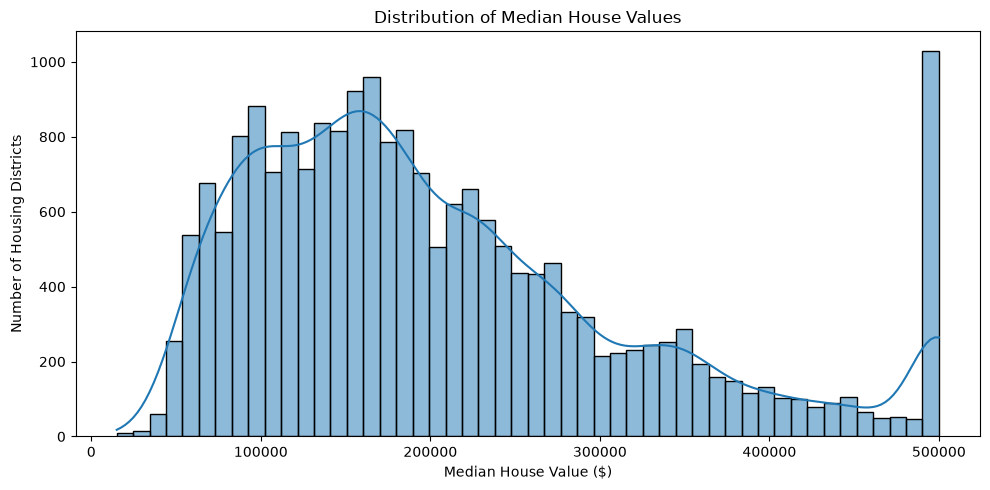

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.histplot(
    data=housing_data,
    x="median_house_value",
    bins=50,
    kde=True
)

plt.title("Distribution of Median House Values")
plt.xlabel("Median House Value ($)")
plt.ylabel("Number of Housing Districts")

plt.tight_layout()
plt.show()

### Correlation Analysis

A correlation heatmap is used to examine linear relationships between numerical features and median house values. This helps identify potentially useful predictors and features that may be strongly related to one another.

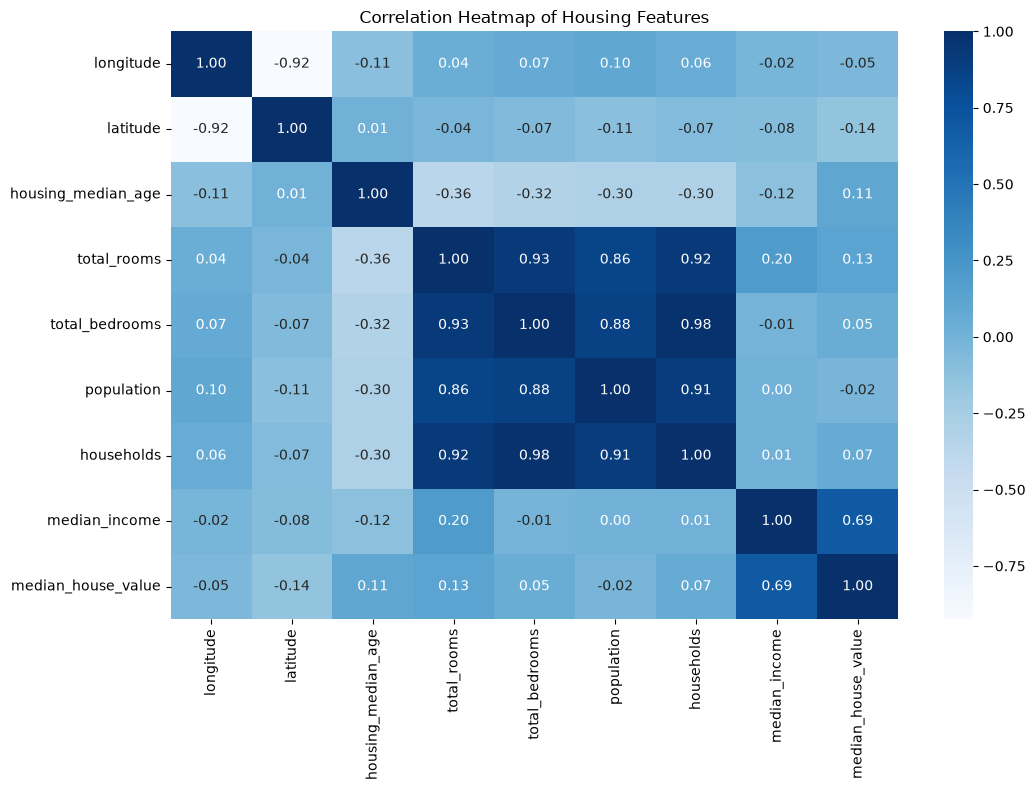

In [4]:
# Select only numerical columns
numerical_data = housing_data.select_dtypes(include="number")

# Calculate the correlation matrix
correlation_matrix = numerical_data.corr()

# Create the correlation heatmap
plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="Blues",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Housing Features")
plt.tight_layout()
plt.show()

## Feature Engineering

Additional features are created to capture relationships between housing characteristics. These include average rooms per household, bedrooms per room, and population per household. The new features may provide more useful information for predicting median house values than the original totals alone.

In [5]:
# Create a separate copy for feature engineering
housing_features = housing_data.copy()

# Calculate average rooms per household
housing_features["rooms_per_household"] = (
    housing_features["total_rooms"] / housing_features["households"]
)

# Calculate the proportion of bedrooms to total rooms
housing_features["bedrooms_per_room"] = (
    housing_features["total_bedrooms"] / housing_features["total_rooms"]
)

# Calculate average population per household
housing_features["population_per_household"] = (
    housing_features["population"] / housing_features["households"]
)

# Display the new features
housing_features[
    [
        "rooms_per_household",
        "bedrooms_per_room",
        "population_per_household"
    ]
].head(10)

,rooms_per_household,bedrooms_per_room,population_per_household
0,6.984127,0.146591,2.555556
1,6.238137,0.155797,2.109842
2,8.288136,0.129516,2.802260
3,5.817352,0.184458,2.547945
4,6.281853,0.172096,2.181467
5,4.761658,0.231774,2.139896
6,4.931907,0.192899,2.128405
7,4.797527,0.221327,1.788253
8,4.294118,0.260274,2.026891
9,4.970588,0.199211,2.172269


## Interaction Feature Experiment

An additional interaction feature is introduced to investigate whether the combined effect of median income and housing age improves prediction accuracy.

The interaction feature is created by multiplying median income by housing median age. A new OLS regression pipeline is trained using the expanded feature set and evaluated against the original OLS baseline.

In [6]:
# Create an interaction feature using income and housing age
housing_features["income_age_interaction"] = (
    housing_features["median_income"]
    * housing_features["housing_median_age"]
)

# Display the new interaction feature
display(
    housing_features[
        ["median_income", "housing_median_age", "income_age_interaction"]
    ].head()
)

,median_income,housing_median_age,income_age_interaction
0,8.3252,41.0,341.3332
1,8.3014,21.0,174.3294
2,7.2574,52.0,377.3848
3,5.6431,52.0,293.4412
4,3.8462,52.0,200.0024


## Data Preparation

### Training and Testing Split

The dataset is divided into 80% training and 20% testing data. This allows the regression models to be trained on one portion of the dataset and evaluated on unseen observations. The split also helps assess how well the models generalize to new data.

In [7]:
from sklearn.model_selection import train_test_split

# Separate input features from the target variable
X = housing_features.drop(columns=["median_house_value"])
y = housing_features["median_house_value"]

# Split the dataset into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Check the dimensions of each dataset
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training targets:", y_train.shape)
print("Testing targets:", y_test.shape)

Training features: (16512, 13)
Testing features: (4128, 13)
Training targets: (16512,)
Testing targets: (4128,)


### Data Preprocessing

The dataset contains missing numerical values and a categorical feature that requires encoding. Missing numerical values are replaced using median imputation, numerical features are standardized, and ocean proximity categories are converted into numerical representations using one-hot encoding.

Preprocessing is fitted using the training data to prevent information from the test set influencing model development.

In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Identify numerical and categorical columns
numerical_columns = X_train.select_dtypes(
    include="number"
).columns.tolist()

categorical_columns = X_train.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

# Create a pipeline for numerical features
numerical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Create a pipeline for categorical features
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine the numerical and categorical pipelines
preprocessor = ColumnTransformer(transformers=[
    ("numerical", numerical_pipeline, numerical_columns),
    ("categorical", categorical_pipeline, categorical_columns)
])

# Display the selected columns
print("Numerical columns:", numerical_columns)
print("\nCategorical columns:", categorical_columns)

Numerical columns: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'rooms_per_household', 'bedrooms_per_room', 'population_per_household', 'income_age_interaction']

Categorical columns: ['ocean_proximity']


## Model Training

### Ordinary Least Squares (OLS) Linear Regression

Ordinary Least Squares Linear Regression is used as the baseline model for predicting median house values. The model learns relationships between the input features and the target variable by minimizing the sum of squared prediction errors.

The preprocessing pipeline is combined with the regression model to ensure that missing-value imputation, feature scaling, and categorical encoding are applied consistently.

In [9]:
from sklearn.linear_model import LinearRegression

# Create the OLS regression pipeline
ols_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

# Train the model using the training data
ols_pipeline.fit(X_train, y_train)

# Predict house values using the testing data
ols_predictions = ols_pipeline.predict(X_test)

# Display the first five predictions
print("Predicted house values:", ols_predictions[:5])
print("Actual house values:", y_test.iloc[:5].values)

Predicted house values: [ 37218.26384014 139754.90357    295755.21092525 280255.75113142
 264184.72967773]
Actual house values: [ 47700.  45800. 500001. 218600. 278000.]


### OLS Model Evaluation

The baseline Linear Regression model is evaluated using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R². These metrics measure prediction accuracy, the impact of larger errors, and how well the model explains variation in median house values.

In [10]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Calculate Mean Absolute Error
ols_mae = mean_absolute_error(y_test, ols_predictions)

# Calculate Root Mean Squared Error
ols_rmse = np.sqrt(mean_squared_error(y_test, ols_predictions))

# Calculate R-squared
ols_r2 = r2_score(y_test, ols_predictions)

# Display the evaluation results
print(f"OLS MAE: ${ols_mae:,.2f}")
print(f"OLS RMSE: ${ols_rmse:,.2f}")
print(f"OLS R²: {ols_r2:.4f}")

OLS MAE: $49,376.49
OLS RMSE: $69,048.19
OLS R²: 0.6362


### Ridge Regression (L2 Regularization)

Ridge Regression is used to investigate whether L2 regularization improves prediction performance compared with the OLS baseline. GridSearchCV is applied to evaluate different alpha values using five-fold cross-validation on the training dataset. The best-performing model is selected based on the lowest cross-validation mean squared error.

In [11]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV

# Create the Ridge regression pipeline
ridge_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", Ridge())
])

# Define alpha values to test
ridge_parameters = {
    "model__alpha": [0.01, 0.1, 1.0, 10.0, 100.0]
}

# Find the best alpha using cross-validation
ridge_search = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid=ridge_parameters,
    cv=5,
    scoring="neg_mean_squared_error",
    n_jobs=-1
)

# Train and tune Ridge regression
ridge_search.fit(X_train, y_train)

# Display the best alpha
print("Best Ridge Alpha:", ridge_search.best_params_)

# Display the best cross-validation RMSE
ridge_cv_rmse = np.sqrt(-ridge_search.best_score_)
print(f"Best Cross-Validation RMSE: ${ridge_cv_rmse:,.2f}")

Best Ridge Alpha: {'model__alpha': 1.0}
Best Cross-Validation RMSE: $67,738.61


### Ridge Model Evaluation

The best Ridge Regression model identified through GridSearchCV is evaluated using the held-out test dataset. MAE, RMSE, and R² are calculated to compare its predictive performance with the OLS baseline.

In [12]:
# Retrieve the best Ridge model from GridSearchCV
best_ridge_model = ridge_search.best_estimator_

# Predict house values using the test dataset
ridge_predictions = best_ridge_model.predict(X_test)

# Calculate evaluation metrics
ridge_mae = mean_absolute_error(y_test, ridge_predictions)
ridge_rmse = np.sqrt(mean_squared_error(y_test, ridge_predictions))
ridge_r2 = r2_score(y_test, ridge_predictions)

# Display Ridge results
print(f"Ridge MAE: ${ridge_mae:,.2f}")
print(f"Ridge RMSE: ${ridge_rmse:,.2f}")
print(f"Ridge R²: {ridge_r2:.4f}")

Ridge MAE: $49,382.63
Ridge RMSE: $69,056.22
Ridge R²: 0.6361


### Lasso Regression (L1 Regularization)

Lasso Regression is used to evaluate the effect of L1 regularization on housing price predictions. Unlike Ridge, Lasso can reduce certain feature coefficients to zero, allowing it to perform implicit feature selection.

GridSearchCV is used to identify the best alpha value through five-fold cross-validation on the training dataset.

In [13]:
from sklearn.linear_model import Lasso

# Create the Lasso regression pipeline
lasso_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", Lasso(max_iter=20000))
])

# Define alpha values to test
lasso_parameters = {
    "model__alpha": [0.01, 0.1, 1.0, 10.0, 100.0]
}

# Search for the best alpha using cross-validation
lasso_search = GridSearchCV(
    estimator=lasso_pipeline,
    param_grid=lasso_parameters,
    cv=5,
    scoring="neg_mean_squared_error",
    n_jobs=-1
)

# Train and tune the Lasso model
lasso_search.fit(X_train, y_train)

# Display the best alpha
print("Best Lasso Alpha:", lasso_search.best_params_)

# Calculate cross-validation RMSE
lasso_cv_rmse = np.sqrt(-lasso_search.best_score_)

print(f"Best Cross-Validation RMSE: ${lasso_cv_rmse:,.2f}")

Best Lasso Alpha: {'model__alpha': 1.0}
Best Cross-Validation RMSE: $67,739.50


### Lasso Model Evaluation

The best Lasso Regression model selected through GridSearchCV is evaluated using the held-out test dataset. MAE, RMSE, and R² are calculated to compare its predictive performance with the OLS and Ridge regression models.

In [14]:
# Retrieve the best Lasso model
best_lasso_model = lasso_search.best_estimator_

# Predict house values using the test dataset
lasso_predictions = best_lasso_model.predict(X_test)

# Calculate evaluation metrics
lasso_mae = mean_absolute_error(y_test, lasso_predictions)
lasso_rmse = np.sqrt(mean_squared_error(y_test, lasso_predictions))
lasso_r2 = r2_score(y_test, lasso_predictions)

# Display Lasso results
print(f"Lasso MAE: ${lasso_mae:,.2f}")
print(f"Lasso RMSE: ${lasso_rmse:,.2f}")
print(f"Lasso R²: {lasso_r2:.4f}")

Lasso MAE: $49,377.34
Lasso RMSE: $69,049.25
Lasso R²: 0.6362


## Model Comparison

The OLS, Ridge, and Lasso regression models are compared using MAE, RMSE, and R² on the held-out test dataset. This allows their predictive performance to be evaluated using consistent metrics.

In [15]:
# Create a table containing the evaluation results
model_results = pd.DataFrame({
    "Model": ["OLS", "Ridge", "Lasso"],
    "MAE": [ols_mae, ridge_mae, lasso_mae],
    "RMSE": [ols_rmse, ridge_rmse, lasso_rmse],
    "R²": [ols_r2, ridge_r2, lasso_r2]
})

# Sort models from lowest to highest RMSE
model_results = model_results.sort_values(
    by="RMSE",
    ascending=True
)

# Display the comparison table
display(model_results.round(2))

,Model,MAE,RMSE,R²
0,OLS,49376.49,69048.19,0.64
2,Lasso,49377.34,69049.25,0.64
1,Ridge,49382.63,69056.22,0.64


## Prediction and Residual Analysis

### Actual vs Predicted House Values

Scatter plots are used to compare actual and predicted median house values for the OLS, Ridge, and Lasso models. A diagonal reference line represents perfect predictions, allowing prediction errors and potential systematic patterns to be identified visually.

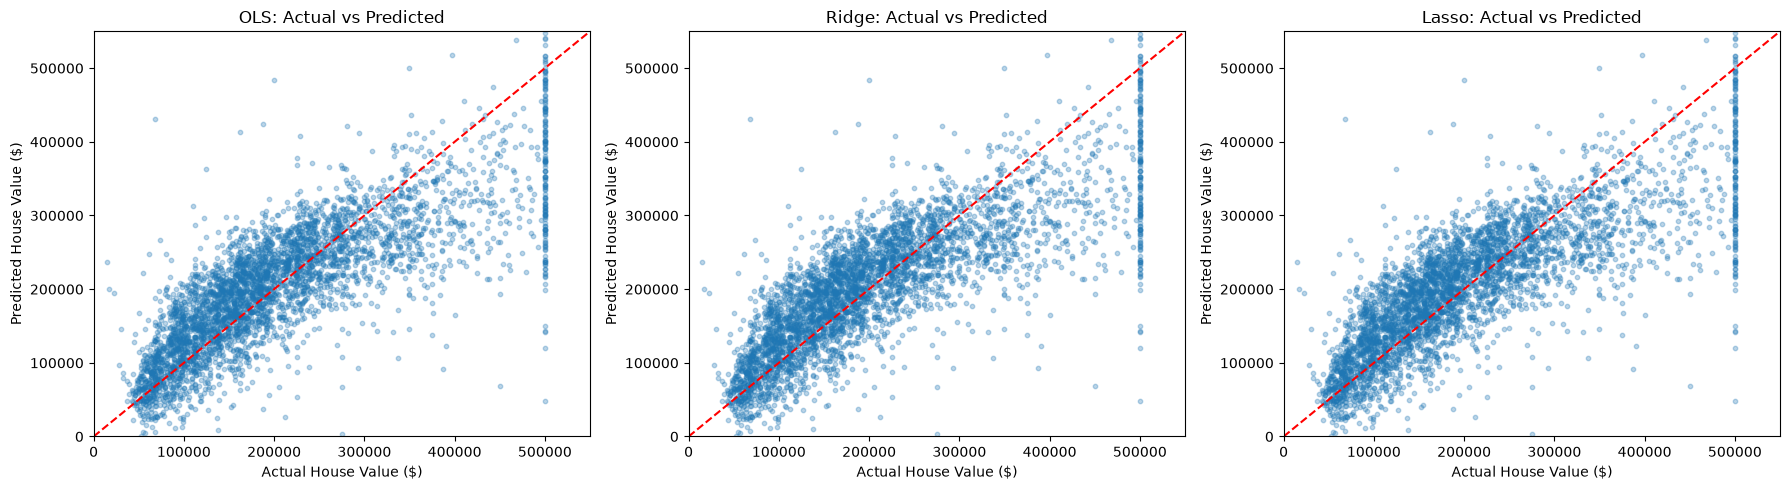

In [16]:
# Store model predictions for plotting
model_predictions = {
    "OLS": ols_predictions,
    "Ridge": ridge_predictions,
    "Lasso": lasso_predictions
}

# Create three plots side by side
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot actual vs predicted values for each model
for ax, (model_name, predictions) in zip(
    axes, model_predictions.items()
):
    ax.scatter(y_test, predictions, alpha=0.3, s=10)

    # Add a line representing perfect predictions
    ax.plot(
        [0, 550000],
        [0, 550000],
        "r--"
    )

    ax.set_title(f"{model_name}: Actual vs Predicted")
    ax.set_xlabel("Actual House Value ($)")
    ax.set_ylabel("Predicted House Value ($)")
    ax.set_xlim(0, 550000)
    ax.set_ylim(0, 550000)

plt.tight_layout()
plt.show()

### Residual Error Distribution

Residuals are calculated as the difference between actual and predicted house values. Their distributions are examined to identify systematic prediction errors, extreme deviations, and differences in error patterns between the OLS, Ridge, and Lasso models.

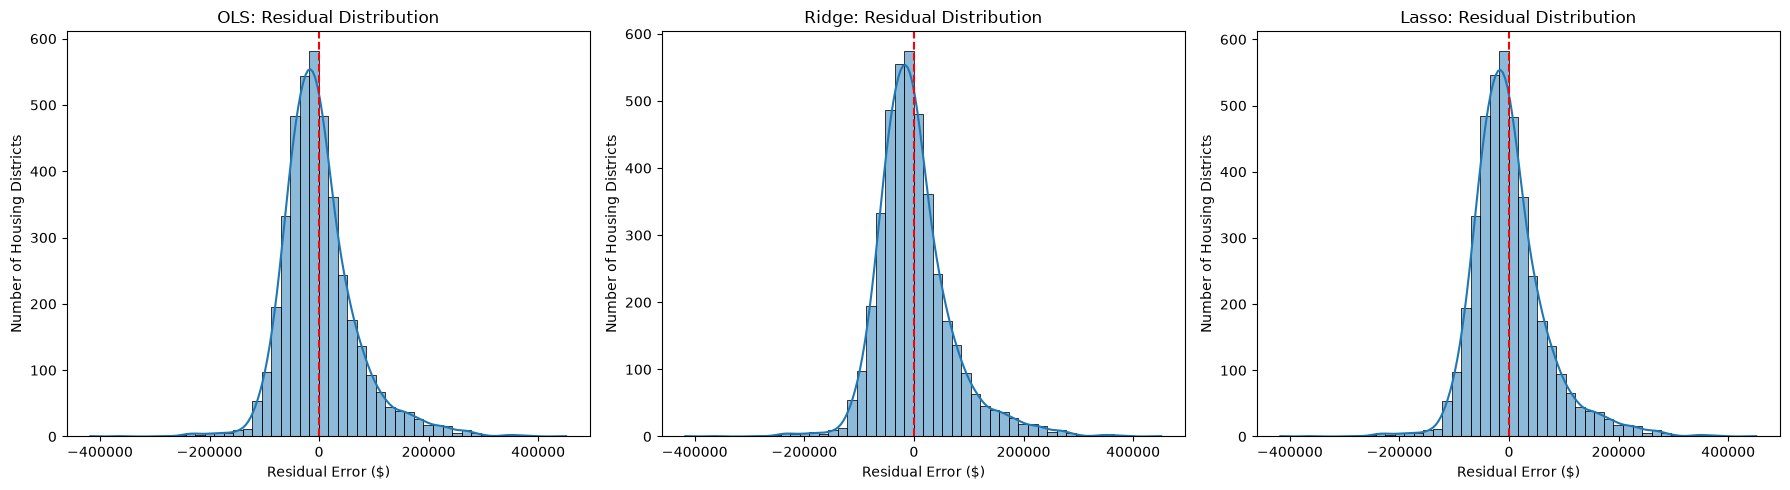

In [17]:
# Calculate residuals for each regression model
model_residuals = {
    "OLS": y_test - ols_predictions,
    "Ridge": y_test - ridge_predictions,
    "Lasso": y_test - lasso_predictions
}

# Create three residual distribution plots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot residual distributions for each model
for ax, (model_name, residuals) in zip(
    axes, model_residuals.items()
):
    sns.histplot(
        residuals,
        bins=50,
        kde=True,
        ax=ax
    )

    # Reference line for zero prediction error
    ax.axvline(0, color="red", linestyle="--")

    ax.set_title(f"{model_name}: Residual Distribution")
    ax.set_xlabel("Residual Error ($)")
    ax.set_ylabel("Number of Housing Districts")

plt.tight_layout()
plt.show()

## Conclusion

This project developed and compared Ordinary Least Squares (OLS), Ridge, and Lasso regression models for predicting median house values using the California Housing dataset.

Exploratory data analysis was performed to examine missing values, feature distributions, and correlations. The dataset was prepared using median imputation, numerical standardization, and one-hot encoding. Additional ratio and interaction features were engineered to capture relationships between housing characteristics.

Ridge and Lasso were tuned using GridSearchCV with five-fold cross-validation.

### Model Performance

| Model | MAE | RMSE | R² |
|---|---:|---:|---:|
| OLS | $49,376.49 | $69,048.19 | 0.64 |
| Ridge | $49,382.63 | $69,056.22 | 0.64 |
| Lasso | $49,377.34 | $69,049.25 | 0.64 |

OLS achieved the lowest MAE and RMSE, although all three models produced nearly identical results. Ridge and Lasso regularization did not provide a meaningful improvement over the OLS baseline.

Introducing an interaction feature between median income and housing age slightly improved the prediction accuracy of all three models. For OLS, RMSE decreased from $69,127.04 to $69,048.19.

The actual-versus-predicted plots and residual distributions highlighted larger prediction errors for certain housing districts, particularly at higher recorded house values. The dataset's upper value cap is also a limitation.

Overall, the results demonstrate that linear regression provides a useful baseline for housing price prediction. Future improvements could include additional feature engineering, nonlinear regression models, and further investigation of extreme values and capped house prices.